# Table of Contents

1. [Code Setup](#Code-Setup)  
   *Overview of this code with allready required packages, installation guides, functions, and desciription of used variables.*

2. [Data Import & Preprocessing](#Import-Data)  
   *Loading raw datasets from netcdf, cleaning, Hobday et al. (2016) MHW calculations, and preparing variables for analysis.*

3. [Model Setup](#Model-Setup)  
   *PyMC model setup.*

4. [Daily Model Run for Short Time Series](#Daily-Model-Run)  
   *Running Model for short time series and comparing to Hobday et al. (2016) Method.*


## Code Setup

### Requirements

This analysis was developed in **Python 3.10**.  
The following Python packages are required to run the code:

- `numpy`
- `pandas`
- `arviz`
- `pymc`
- `matplotlib`
- `scipy`
- `seaborn`
- `xarray`
- `fastdtw`
- `nutpie`
- `corner`
- `marineHeatWaves` (Freely on Github available Hobday et al. (2016) MHW detection method)

... standard Python libraries (`os`, `sys`, `datetime`, `collections`, `string`, `pickle`, etc...) are used and do not require installation.



### Installation
The safest way to install everything is by creating a **new conda environment**:


```bash
# 1. Create a new environment
conda create -n pymc_env python=3.10 -c conda-forge
conda activate pymc_env
conda config --env --set channel_priority strict
# 2. Install core dependencies
conda install -c conda-forge numpy pandas arviz pymc matplotlib scipy seaborn xarray fastdtw pyarrow graphviz python-graphviz nutpie corner
# 3. Fix BLAS to avoid warnings and improve performance
conda install -c conda-forge "blas=*=openblas"
# 4. Install marineHeatWaves from GitHub
pip install git+https://github.com/ecjoliver/marineHeatWaves.git
```

### Graphviz Requirement
PyMC uses **Graphviz** to render model graphs. Graphviz is a system-level program (not a standard Python package), which means it must be installed separately.
- Graphviz (https://graphviz.org/download/)
- This is only necessary if you want to visualise the PyMC model graph (see 4.1.2. Save Model Graph).
- It is not necessary for the rest of the code or the PyMC model.



### Import Packages

In [1]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
from matplotlib.cm import get_cmap
from scipy.stats import norm
import scipy.stats as stats
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr
from datetime import datetime
from scipy.signal import find_peaks
from scipy.ndimage import label
from fastdtw import fastdtw
from collections import defaultdict
import string
import pickle
import matplotlib.patheffects as PathEffects
from scipy.stats import gaussian_kde
from statsmodels.tsa.stattools import acf
from Functions_PyMC_MHWdetection import *
import corner
from matplotlib.lines import Line2D



# Add Graphviz binaries to PATH so PyMC can find 'dot.exe'
# Adjust this path if Graphviz is installed in a different location
os.environ["PATH"] += os.pathsep + r"C:\Users\24048369\OneDrive - The University of Western Australia\Graphviz-12.2.1-win64\bin"

sys.path.append('C:/Users/24048369/OneDrive - The University of Western Australia/Desktop/Sina/marineHeatWaves-python/')
import marineHeatWavesCopy as mhw_hobday



### Important Functions

In [3]:
# RANDOM_SEED = 8929
# rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)


def sampler_kwargs():
    return dict(
        nuts_sampler="nutpie",
        chains=4,
        draws=500,
        random_seed=42,
        nuts_sampler_kwargs={"backend": "numba", "gradient_backend": "numba"},
    )

current_folder = os.getcwd()
# Define the folder name where figures will be saved
file_folder = os.path.join(f'{current_folder}') #current_folder
Folder_name = 'Figures_ShortTimeSeries'

figures_folder = os.path.join(f'{current_folder}/{Folder_name}') #crete new folder for figures in current folder 
# Create the folder if it does not exist
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(file_folder, exist_ok=True)
print(f"Figures will be saved in: {figures_folder}")
print(f"Files are in: {file_folder}")

Figures will be saved in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection/Figures_ShortTimeSeries
Files are in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection


### Explanation of all xarrays and dataframes used in this code

- ds_raw        = raw loaded dataset from netcdf (xarray)  
- ds_raw_C      = averaged lon/lat dataset from netcdf in degree Celsius (xarray)  
- df_C          = dataframe of averaged lon/lat temp in degree Celsius (pandas dataframe)  
- df_w          = dataframe temperature timeseries weekly data with temperature, mean climatology and threshold (pandas dataframe)  
- mhw_df        = dataframe with climatology (seas) and threshold (thresh) based whole timeseries baseline)  
- df_C_roll     = dataframe daily temperature whole timeseries with rolling mean over 7 days (pandas dataframe)  



# Import Data


In [5]:
# Your file
file_path = f"{file_folder}/data/3-SouthWA.nc"

# Open dataset
ds_raw = xr.open_dataset(file_path)


## Plot timeseries

Length ds_raw_C: 5.00 yrs
Mean temperature: 20 °C


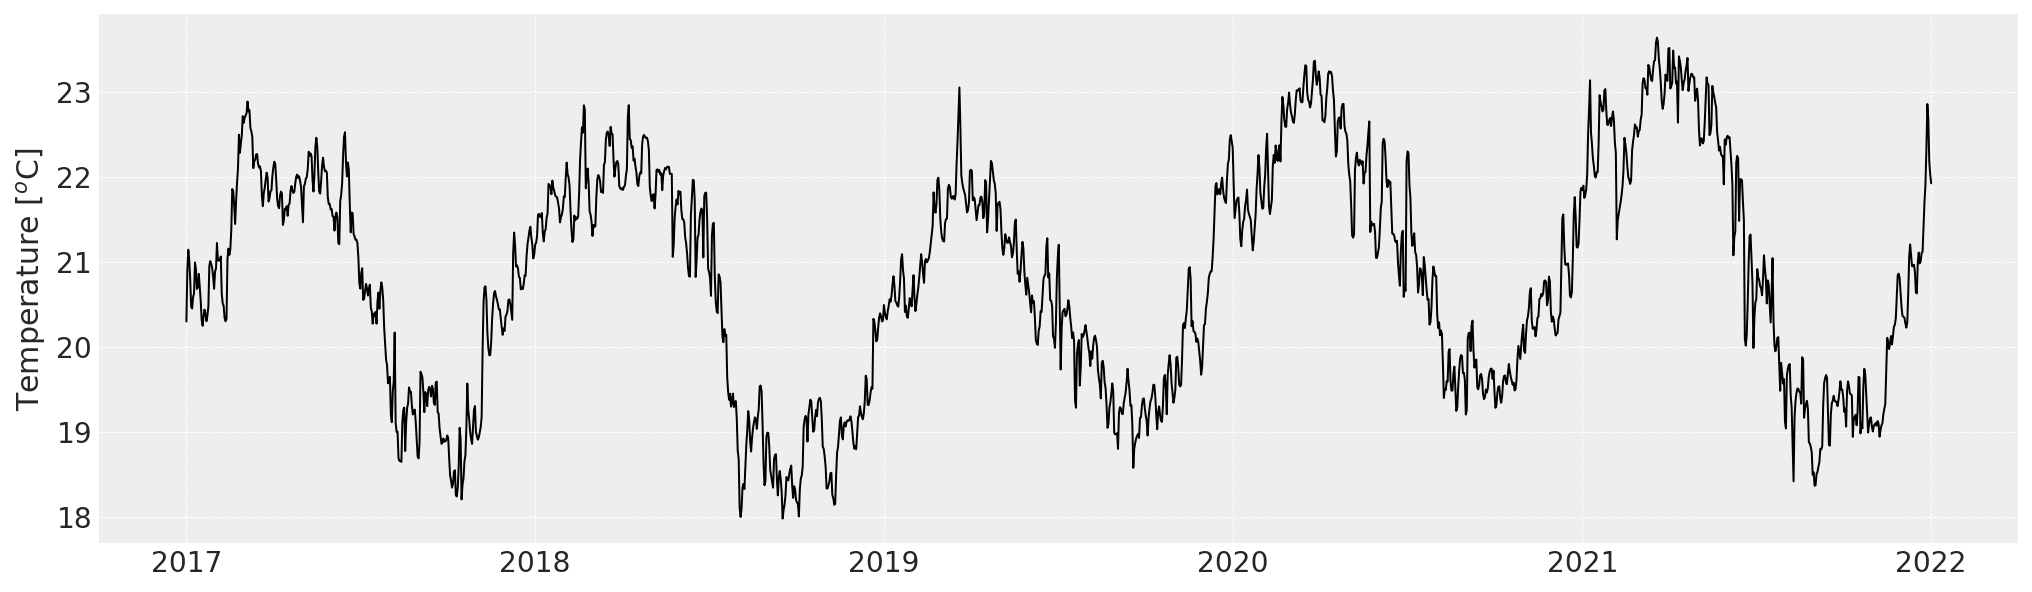

In [6]:
# ------------------------------------------------------------------------------
# 1. Load Timeseries, for this example here: Extract Copernicus SST (°C) for 2019–2025
# ------------------------------------------------------------------------------
ds_raw_C = (
    ds_raw
    .sel(time=slice(pd.to_datetime("2017-01-01"), pd.to_datetime("2022-01-01")))
    .analysed_sst
    .mean("latitude")    # average spatially over latitude
    .mean("longitude")   # average spatially over longitude
    - 273.15             # convert from Kelvin to Celsius
)

print(f"Length ds_raw_C: {len(ds_raw_C) / 365.25:.2f} yrs")

# ------------------------------------------------------------------------------
# 2. Extract time and temperature arrays
# ------------------------------------------------------------------------------

time_array_cop = ds_raw_C.time
temp_array_cop = ds_raw_C.values

print(f"Mean temperature: {np.floor(np.nanmean(temp_array_cop)):.0f} °C")

# ------------------------------------------------------------------------------
# 3. Plot raw SST time series
# ------------------------------------------------------------------------------

plt.plot(time_array_cop, temp_array_cop, color="black", lw=1)
plt.ylabel("Temperature [$^{o}$C]")

# ------------------------------------------------------------------------------
# 4. Save figure
# ------------------------------------------------------------------------------

plt.savefig(f"{figures_folder}/timeseries_raw.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_raw.pdf", dpi=300, bbox_inches="tight")


## Create weekly data for uncertainty analysis

D
Start date: 2017-01-01 00:00:00
End date: 2022-01-01 00:00:00


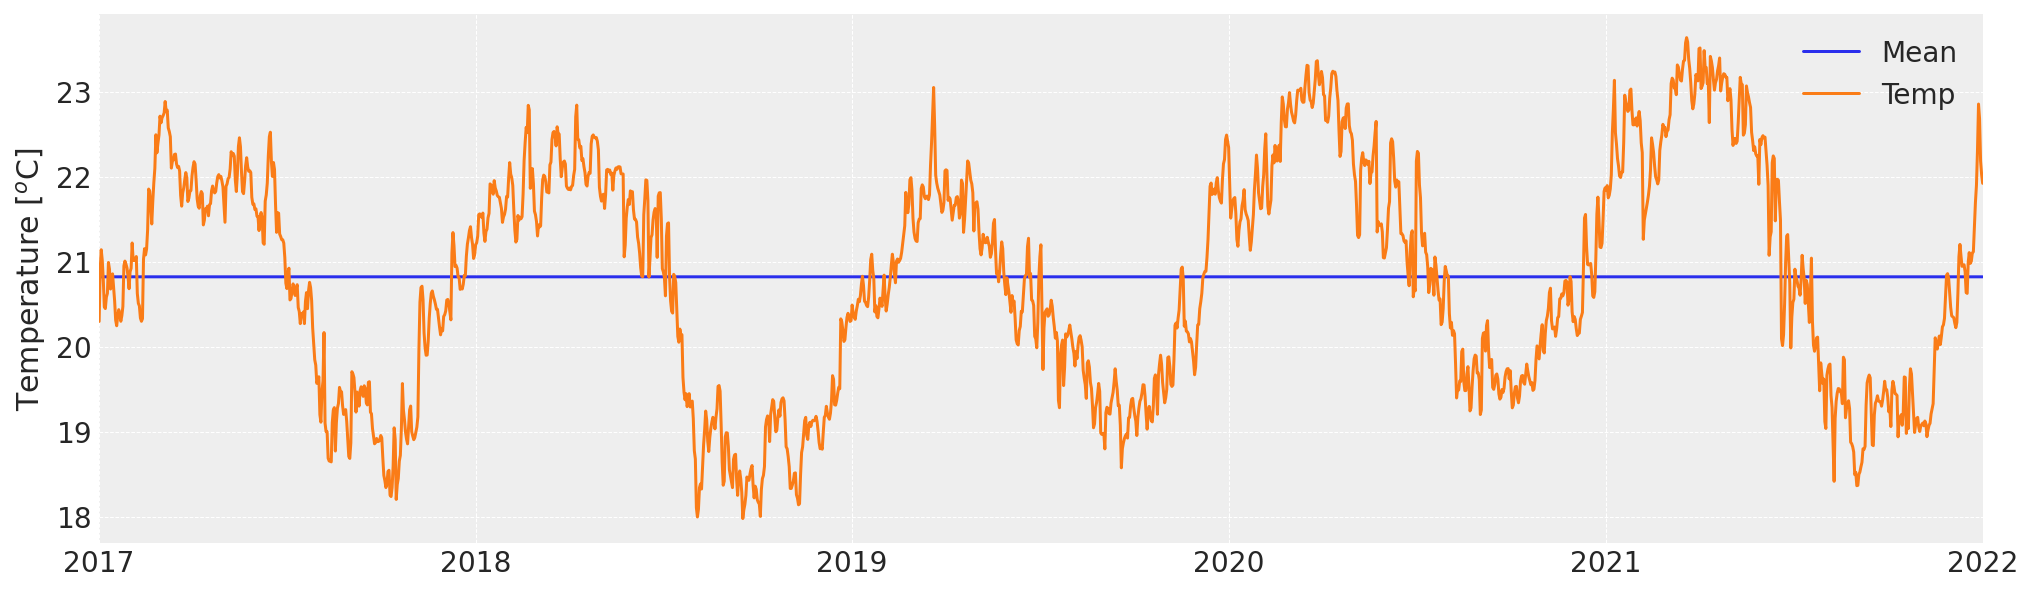

In [7]:
# ------------------------------------------------------------------------------
# 1. Build daily temperature DataFrame
# ------------------------------------------------------------------------------
df_C = pd.DataFrame({
    "Mean": np.zeros(len(temp_array_cop)) + np.nanmean(temp_array_cop),  # global mean
    "Temp": temp_array_cop                                               # daily temps
}, index=time_array_cop)

# ------------------------------------------------------------------------------
# 2. Convert to weekly time series
# ------------------------------------------------------------------------------
df_w = df_C.resample("D").interpolate("linear").copy()

# ------------------------------------------------------------------------------
# 3. Plot weekly time series
# ------------------------------------------------------------------------------
df_w.plot()
plt.ylabel("Temperature [$^{o}$C]")

# Save weekly series to CSV
df_w.to_csv(f"{figures_folder}/Weekly_timeseries.csv")

# ------------------------------------------------------------------------------
# 4. Get seasonal length & frequency metadata
# ------------------------------------------------------------------------------
seas_length, freq = get_freq_seaslenght(df_w.index)
print(freq)
print(f"Start date: {df_w.index[0]}")
print(f"End date: {df_w.index[-1]}")

# ------------------------------------------------------------------------------
# 5. Save plots
# ------------------------------------------------------------------------------
plt.savefig(f"{figures_folder}/timeseries_{freq}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_{freq}.pdf", dpi=300, bbox_inches="tight")

## Hobday 30yrs Climatology and Threshold

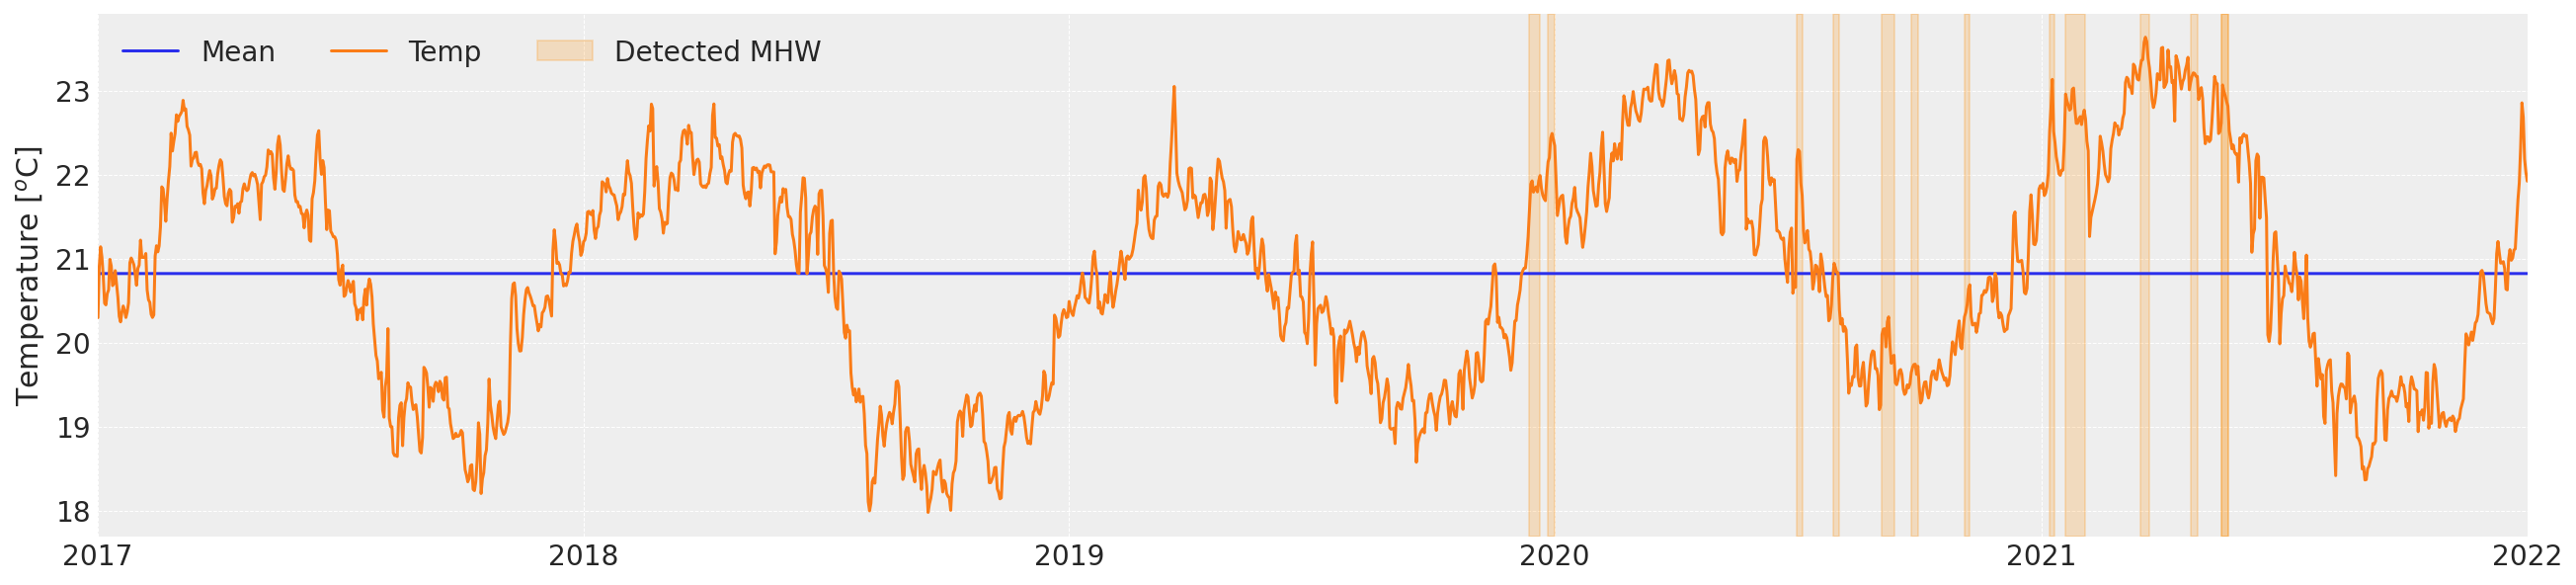

In [8]:
# ------------------------------------------------------------------------------
# 1. Calculate Hobday climatology & threshold 
# ------------------------------------------------------------------------------
df_C_roll = df_C.copy()

# Compute marine heatwaves (MHWs), climatology, and threshold
mhws_, clim_, times_dates_mhw_ = comparing_to_Hobday(df_C_roll.Temp)

# Save detected MHW dictionary
np.save(f"{figures_folder}/mhw_dict.npy", mhws_)

# Save daily climatology & threshold to CSV
mhw_df = pd.DataFrame({"seas": clim_["seas"], "thresh": clim_["thresh"]}, index=pd.to_datetime(times_dates_mhw_))
mhw_df.to_csv(f"{figures_folder}/Daily_Hobday.csv")

# ------------------------------------------------------------------------------
# 2. Add weekly climatology & threshold to weekly dataset
# ------------------------------------------------------------------------------
df_C_roll["seas"] = mhw_df["seas"].resample(freq).interpolate("linear")
df_C_roll["thresh"] = mhw_df["thresh"].resample(freq).interpolate("linear")

# ------------------------------------------------------------------------------
# 3. Plot time series with detected MHWs
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 1, figsize=(18, 4))

# Plot weekly time series with climatology & threshold
df_w.plot(ax=ax)

# Shade detected MHW periods
for ds_start, ds_end in zip(mhws_["date_start"], mhws_["date_end"]):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color="darkorange", alpha=0.2)
# Add legend label on last shaded event
ax.axvspan( pd.Timestamp(ds_start), pd.Timestamp(ds_end), color="darkorange", alpha=0.2, label="Detected MHW")

# Axis labels & legend
ax.set_ylabel("Temperature [$^{o}$C]")
ax.legend(ncols=5)

# Save high-resolution plots
plt.savefig(f"{figures_folder}/timeseries_with_climThresh_{freq}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{figures_folder}/timeseries_with_climThresh_{freq}.pdf", dpi=300, bbox_inches="tight")

# ------------------------------------------------------------------------------
# 4. Save weekly dataset with climatology & threshold
# ------------------------------------------------------------------------------
df_w.to_csv(f"{figures_folder}/Weekly_timeseries_withClimThresh.csv")


## Based on Climatology and Threshold suggest right Harmonics Order

Seasonal length: 365.25


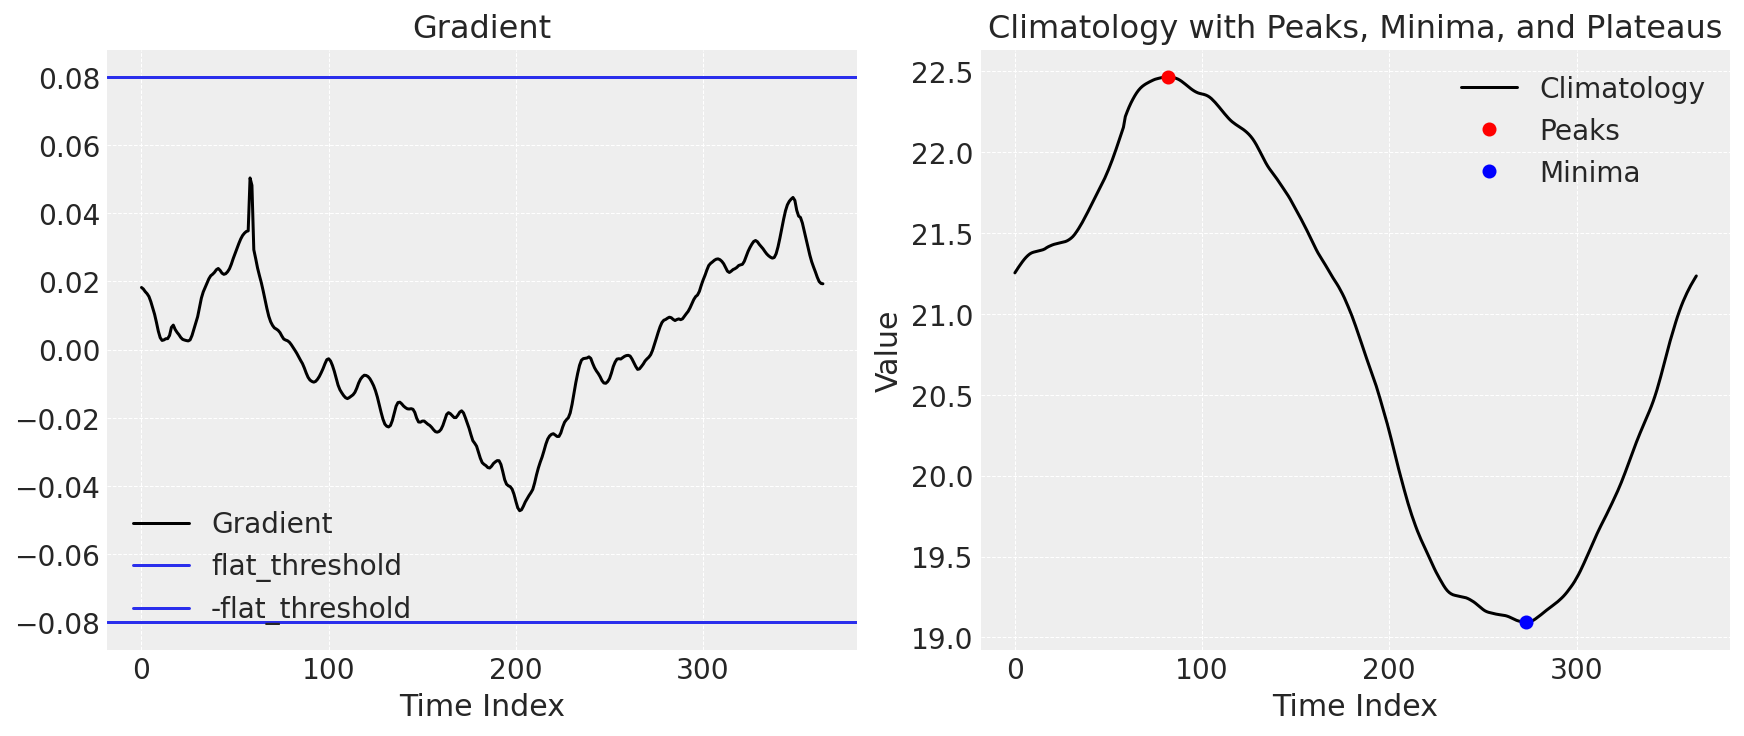

Final suggested harmonics n_order: 1 to 2


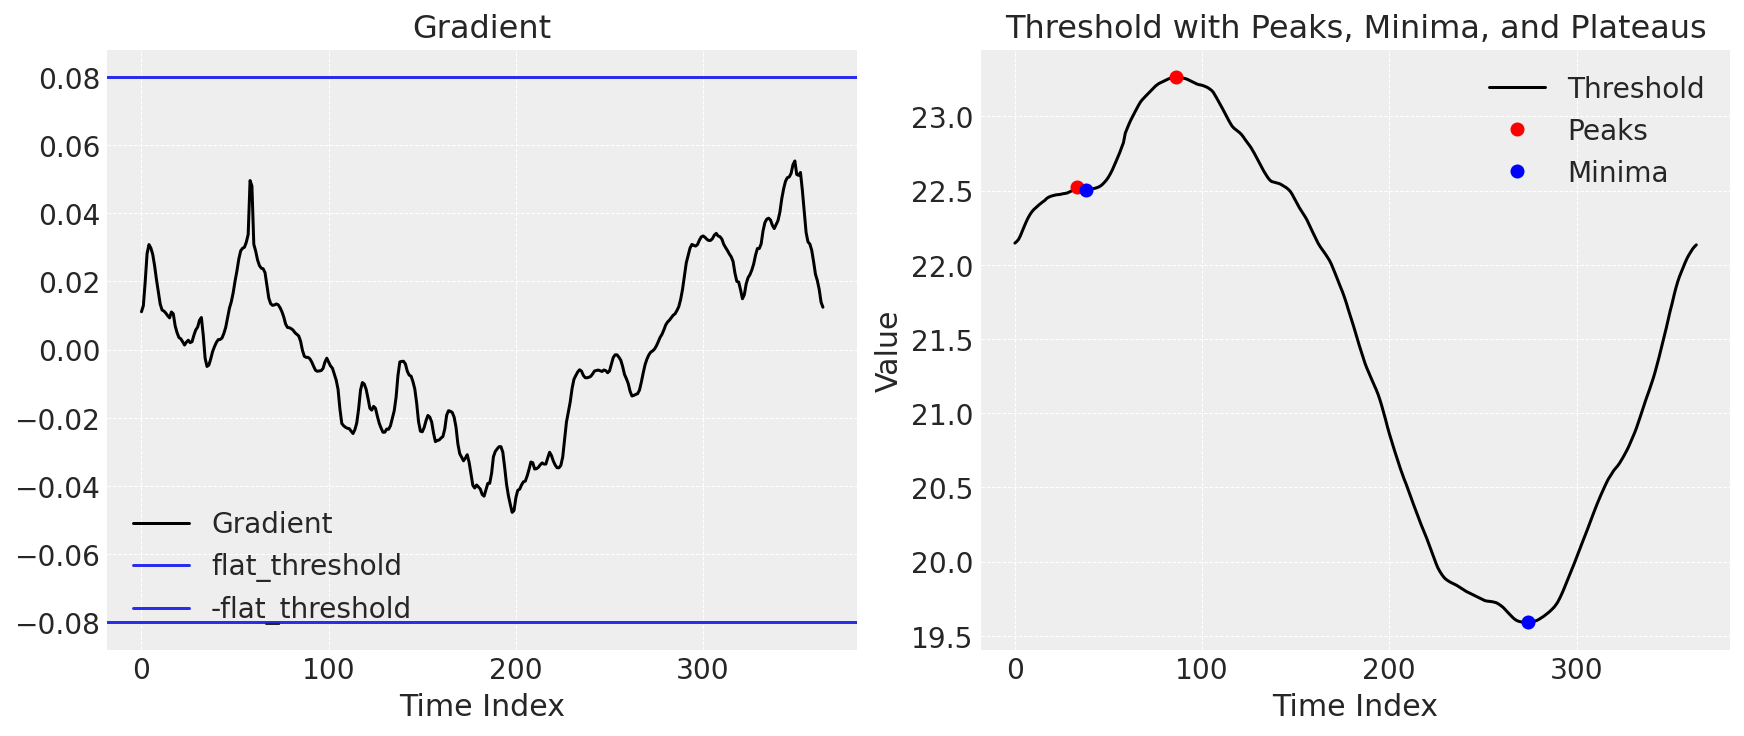

Final suggested harmonics n_order: 2 to 3


In [9]:
seas_length, freq = get_freq_seaslenght(df_C_roll.index)
print("Seasonal length:", seas_length)
final_n_order = detect_peaks_minima_plateaus(df_C_roll['seas'][:int(seas_length)], var = 'Climatology')
final_n_order2 = detect_peaks_minima_plateaus(df_C_roll['thresh'][:int(seas_length)], var = 'Threshold')

# Model Setup

## PyMC Model function

In [11]:
## OG and works perfectlY! but wiht SutdenT at the moment
def pymc_function(input_data, n_order = 1, mean_temp = 15):
    
    ## 1. Check timestep and seasonal length
    seas_length, freq = get_freq_seaslenght(input_data.index)
    
    ## 2. Generating fourier features
    # t_data = list(range(len(input_data)))
    t_data = np.arange(len(input_data))
    
    periods = np.array(t_data) / seas_length
    ff = pd.DataFrame( { f"{func}_order_{order}": getattr(np, func)(2 * np.pi * periods * order)
            for order in range(1, n_order + 1) for func in ("sin", "cos")})
    ff = ff.to_numpy().T

    ### 3. Define model
    with pm.Model() as PyMCmodel:
        pass

    ### 4. Add coordinates to model   
    PyMCmodel.add_coord("obs_id", t_data)
    PyMCmodel.add_coord("fourier_features", np.arange(len(ff)))

    ### 5. Build model
    with PyMCmodel:
        #### --- Data containers
        fourier_terms = pm.Data ("fourier_terms", ff)

        #### --- Priors
        # alpha is the long-term baseline
        alpha = pm.Normal('alpha', mu=mean_temp, sigma=2 )
        # sigma is the high-frequency noise
        sigma = pm.TruncatedNormal('sigma', mu=1.5, sigma=0.5, lower=0)
            

        #### --- Seasonality (Fourier Terms)
        beta_fourier = pm.Normal(name="beta_fourier", mu=0, sigma=2, dims="fourier_features")
        seasonality = pm.Deterministic("seasonality", pm.math.dot(beta_fourier, fourier_terms), dims="obs_id")
    
        #### --- The Combined Mean (mu)     
        mu = pm.Deterministic("mu", alpha + seasonality, dims="obs_id")

     
        # #### --- The Likelihood
        outcome = pm.Normal("likelihood", mu=mu, sigma=sigma, observed=input_data.values, dims="obs_id") 

    
        #### --- Sampling OG Version
        idata = pm.sample_prior_predictive()
        idata.extend(pm.sample(**sampler_kwargs()))
        idata.extend(pm.sample_posterior_predictive(idata))
        
        
    return idata, PyMCmodel

# Daily Model Run

##  Running Model single time

In [12]:
label_years = '5yrs'
mean_temperature = 20 

print(f"Harmonics order: {final_n_order}")
print(f"Mean Temperature: {mean_temperature}")

Harmonics order: 2
Mean Temperature: 20


In [13]:
idata, model = pymc_function(df_C_roll.Temp, n_order=final_n_order, mean_temp = mean_temperature)

C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Sampling: [alpha, beta_fourier, likelihood, sigma]


Progress,Draws,Divergences,Step Size,Gradients/Draw
,1500,0,0.97,3
,1500,0,0.98,3
,1500,0,1.00,3
,1500,0,0.99,3


Sampling: [likelihood]


C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\rich\live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

## Show Uncertainty plot

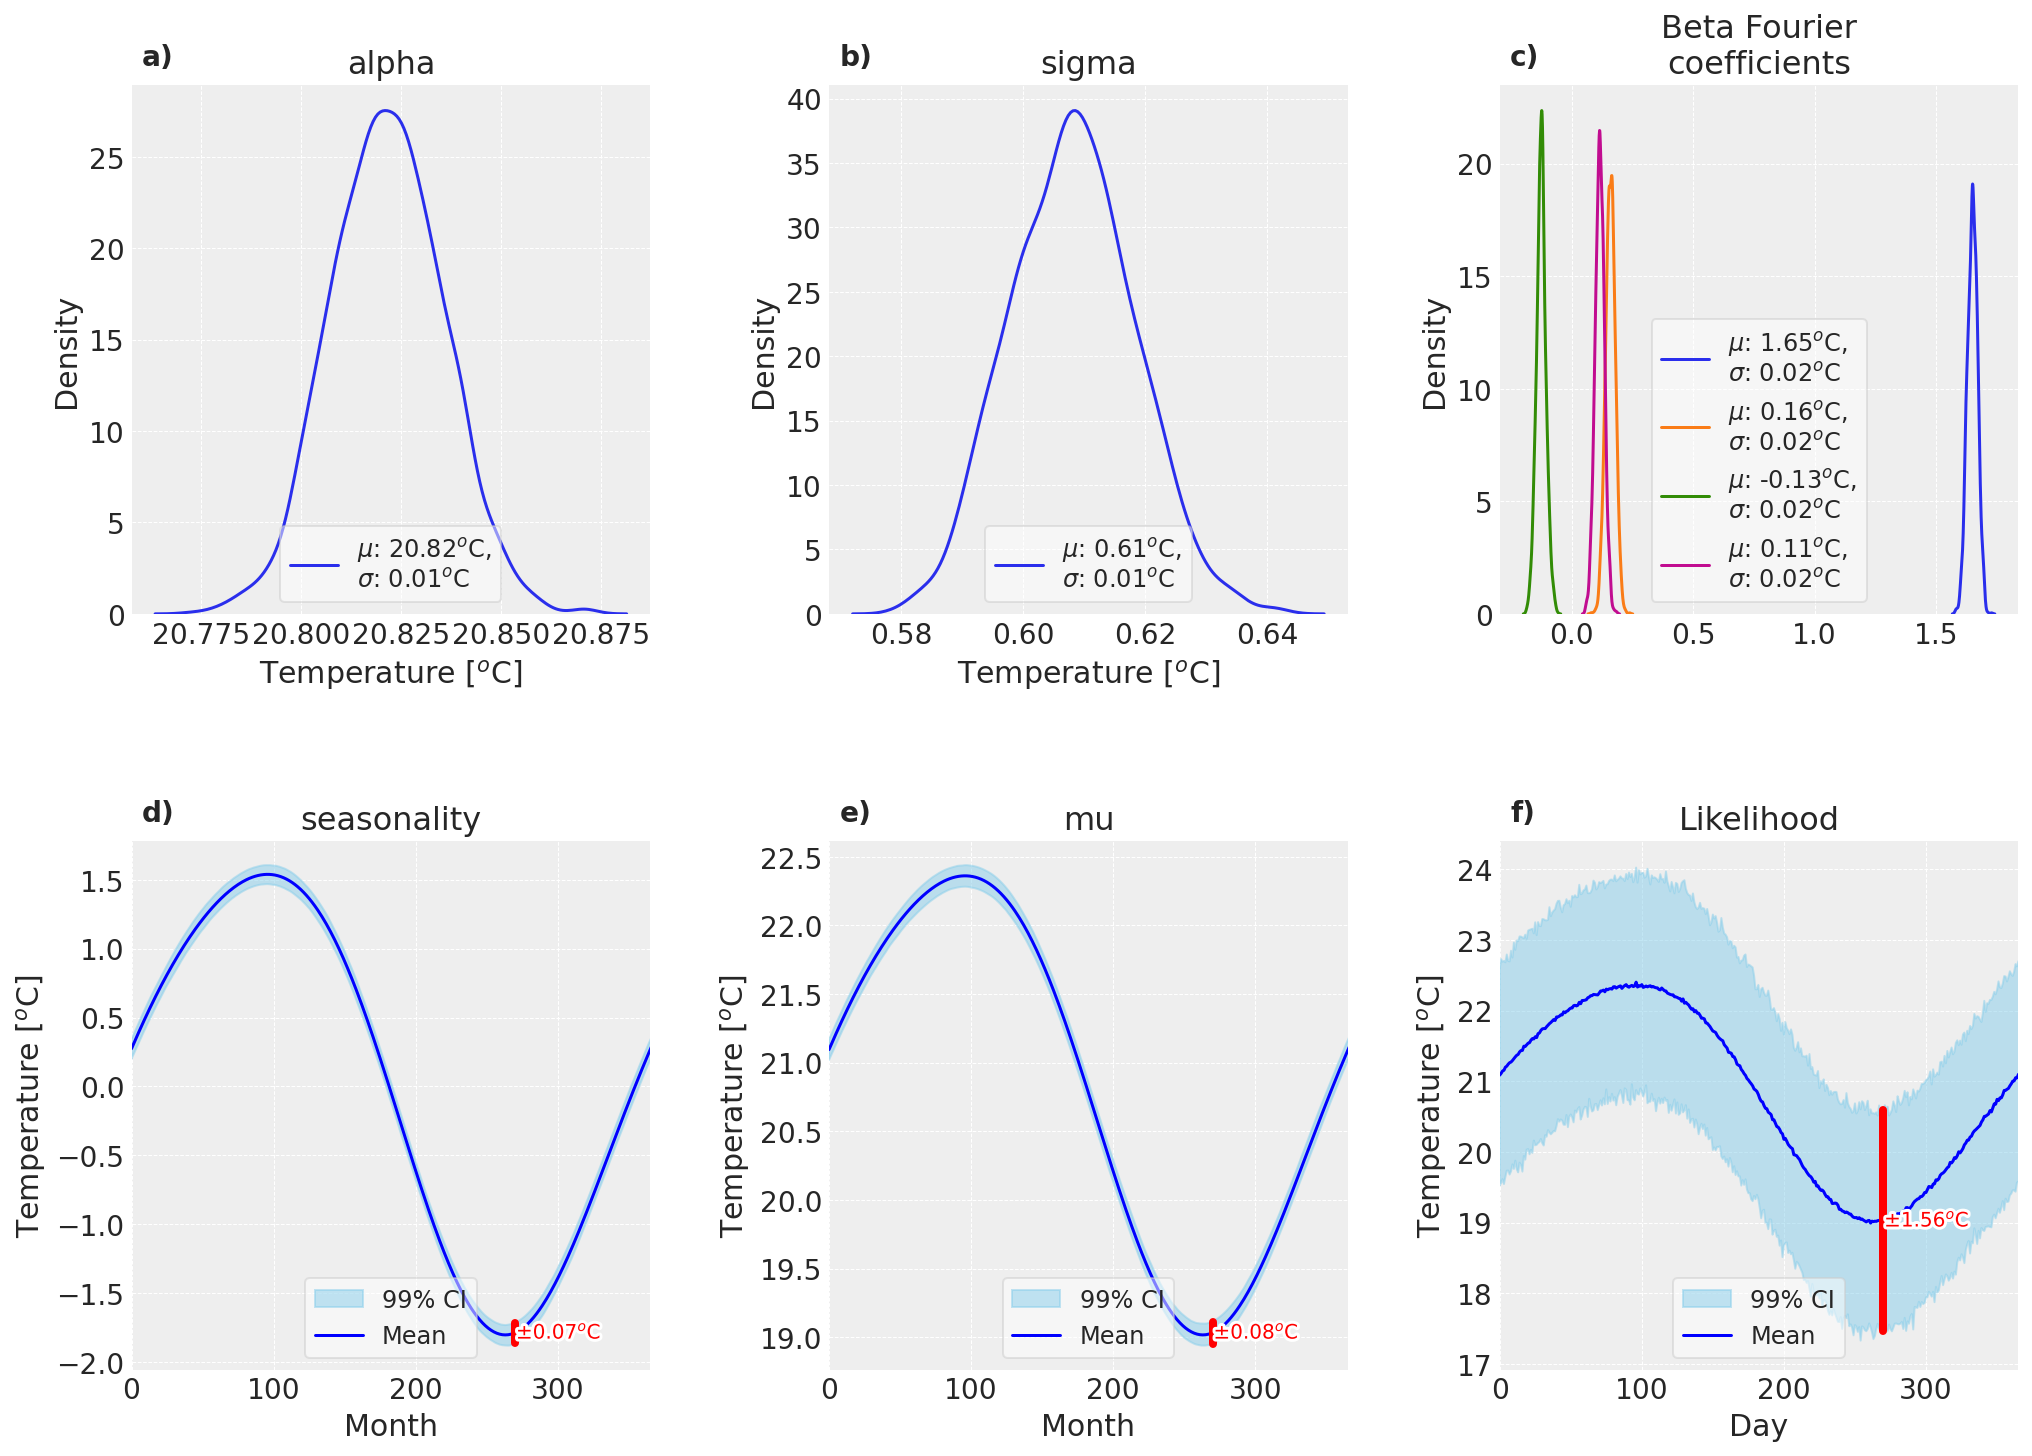

In [14]:
# Variables to analyse
scalar_vars = ["alpha", "sigma"]             # Single-value parameters
time_vars = ["seasonality", "mu"]            # Time-dependent parameters

# Count of subplots
n_scalar = len(scalar_vars)
n_time = len(time_vars)
total = n_scalar + n_time + 1  # +1 for likelihood plot

# Create figure with subplots (2 rows × 4 columns)
fig, axes = plt.subplots(2, 3, figsize=(14, 10), gridspec_kw={'wspace': 0.1, 'hspace': 0.15})
axes = axes.flatten()

# ------------------------------------------------------------------------------
# 1. Scalar variables – posterior distributions
# ------------------------------------------------------------------------------
for i, var in enumerate(scalar_vars):
    ax = axes[i]
    # Flatten MCMC chains and draws
    values = idata.posterior[var].stack(sample=("chain", "draw")).values
    # Fit normal distribution to posterior samples
    mu, std = norm.fit(values)
    # Kernel density estimate (KDE) of posterior distribution
    sns.kdeplot(values, label=f"$\mu$: {mu:.2f}$^{{o}}$C,\n$\sigma$: {std:.2f}$^{{o}}$C",  linestyle="-", ax=ax )
    ax.set_title(f"{var}")
    ax.set_xlabel('Temperature [$^{o}$C]')
    ax.legend( fontsize=12, frameon=True, framealpha=0.5, facecolor='white', loc='lower center')


ax = axes[2]  
values = idata.posterior['beta_fourier'].stack(sample=("chain", "draw")).values
n_coeff = values.shape[0]

# Plot distribution for each Fourier coefficient
for i in range(n_coeff):
    coef_values = values[i, :]
    mu, std = norm.fit(coef_values)
    sns.kdeplot( coef_values,label=f"$\mu$: {mu:.2f}$^{{o}}$C,\n$\sigma$: {std:.2f}$^{{o}}$C",linestyle="-", ax=ax )

ax.set_title("Beta Fourier\ncoefficients")
ax.legend( fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')


for j, var in enumerate(time_vars):
    ax = axes[n_scalar + j + 1]

    # Extract values (obs × samples)
    values = idata.posterior[var].stack(sample=("chain", "draw")).values
    mean = values.mean(axis=1)
    lower = np.percentile(values, 0.5, axis=1)
    upper = np.percentile(values, 99.5, axis=1)

    # Plot mean and uncertainty band
    ax.fill_between(range(len(mean)), lower, upper, color='skyblue', alpha=0.5, label='99% CI')
    ax.plot(mean, color='blue', label='Mean')

    # Reference bar showing average uncertainty magnitude
    ci_width = np.mean(upper - lower) / 2
    x_pos = 270
    y_pos = mean[x_pos]
    ax.plot([x_pos, x_pos], [y_pos - ci_width, y_pos + ci_width], color='red', lw=4)
    txt = ax.text(x_pos + 0.5, y_pos, f"±{ci_width:.2f}$^{{o}}$C", color='red', va='center')
    txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

    ax.set_xlabel("Month")
    ax.set_title(var)
    ax.set_ylabel('Temperature [$^{o}$C]')
    ax.set_xlim(0, 365)
    ax.legend( fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')

ax = axes[n_scalar + j + 2]

values = idata.posterior_predictive['likelihood'].stack(sample=("chain", "draw")).values
mean = values.mean(axis=1)
lower = np.percentile(values, 0.5, axis=1)
upper = np.percentile(values, 99.5, axis=1)

# Plot mean and uncertainty band
ax.fill_between(range(len(mean)), lower, upper, color='skyblue', alpha=0.5, label='99% CI')
ax.plot(mean, color='blue', label='Mean')

# Add reference bar for uncertainty
ci_width = np.mean(upper - lower) / 2
x_pos = 270
y_pos = mean[x_pos]
ax.plot([x_pos, x_pos], [y_pos - ci_width, y_pos + ci_width], color='red', lw=4)
txt = ax.text(x_pos + 0.5, y_pos, f"±{ci_width:.2f}$^{{o}}$C", color='red', va='center')
txt.set_path_effects([PathEffects.withStroke(linewidth=3, foreground="white")])

ax.set_xlabel("Day")
ax.set_title("Likelihood")
ax.set_ylabel('Temperature [$^{o}$C]')
ax.set_xlim(0, 365)
ax.legend(fontsize=12, frameon=True, framealpha=0.5,facecolor='white', loc='lower center')

# Add panel labels (a, b, c, …)
labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axes.flat)]]
for ax, lab in zip(axes.flat, labels):
    ax.text( 0.02, 1.08, lab, transform=ax.transAxes,fontsize=14, fontweight='bold', va='top',
            ha='left',bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))

# Save 
plt.savefig(os.path.join(figures_folder, "UncertaintyExampleParameters.png"), dpi=300)
plt.savefig(os.path.join(figures_folder, "UncertaintyExampleParameters.pdf"), dpi=300)
plt.show()


C:\Users\24048369\AppData\Local\Temp\ipykernel_37852\263398508.py:77: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


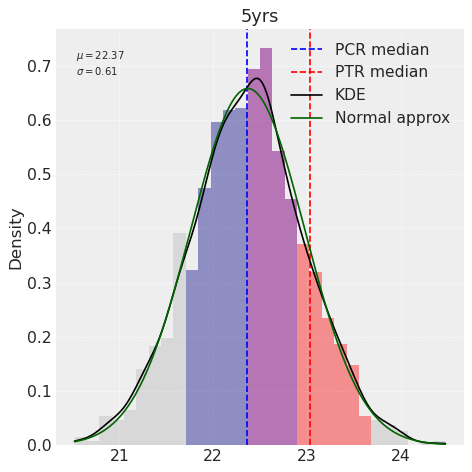

In [15]:
# Choose a specific day to highlight (index in time_array)
day_idx = 100  

# Create figure
fig, ax0 = plt.subplots(1, 1, figsize=(6, 6), dpi=80, sharey=True, sharex=True)


# Posterior predictive likelihood samples for the chosen day
likelihood_samples = (
    idata.posterior_predictive["likelihood"]
    .stack(sample=("chain", "draw"))
    .values[day_idx, :]
)

# Extract PCR & PTR values (quantile-based uncertainty bands)
PCR, PTR, time_array = get_PCRs_and_PTR(idata, df_C_roll)
pcr_val = PCR[:, day_idx]
ptr_val = PTR[:, day_idx]

# Compute 99% credible intervals (0.5–99.5th percentiles)
pcr_low, pcr_high = np.percentile(pcr_val, [0.5, 99.5])
ptr_low, ptr_high = np.percentile(ptr_val, [0.5, 99.5])

# Plot base histogram of likelihood samples
counts, bins, patches = ax0.hist(likelihood_samples, bins=30, density=True, alpha=0.2, color="gray")

# Color histogram bars depending on PCR/PTR overlap
for patch, left, right in zip(patches, bins[:-1], bins[1:]):
    in_pcr = (right >= pcr_low) and (left <= pcr_high)
    in_ptr = (right >= ptr_low) and (left <= ptr_high)

    if in_pcr and in_ptr:
        patch.set_facecolor("purple")   # Overlapping PCR & PTR
        patch.set_alpha(0.5)
    elif in_pcr:
        patch.set_facecolor("navy")     # PCR only
        patch.set_alpha(0.4)
    elif in_ptr:
        patch.set_facecolor("red")      # PTR only
        patch.set_alpha(0.4)

# Median reference lines
ax0.axvline(np.median(pcr_val), color="blue", linestyle="--", label="PCR median")
ax0.axvline(np.median(ptr_val), color="red", linestyle="--", label="PTR median")

# KDE of likelihood samples
kde = gaussian_kde(likelihood_samples)
x_vals = np.linspace(likelihood_samples.min(), likelihood_samples.max(), 200)
ax0.plot(x_vals, kde(x_vals), color="black", lw=1.5, label="KDE")

# Normal approximation for comparison
mu = np.mean(likelihood_samples)
sigma = np.std(likelihood_samples)
ax0.plot(x_vals, norm.pdf(x_vals, mu, sigma), color="darkgreen", lw=1.5, label="Normal approx")

# Annotate mean & std
ax0.text( 0.05, 0.95, f"$\mu={mu:.2f}$\n$\sigma={sigma:.2f}$", transform=ax0.transAxes, fontsize=9, va="top")

ax0.set_title(label_years)
ax0.set_ylabel("Density")
ax0.legend()

plt.tight_layout()
plt.show()

## Saving Model Output

In [16]:
# if you wanna save the output 
idata.to_netcdf( f'{figures_folder}/Idata_{label_years}.nc')
df_C_roll.to_pickle(f'{figures_folder}/df_C_roll_{label_years}.pkl')


## Plot short PTR,PCR and HPS


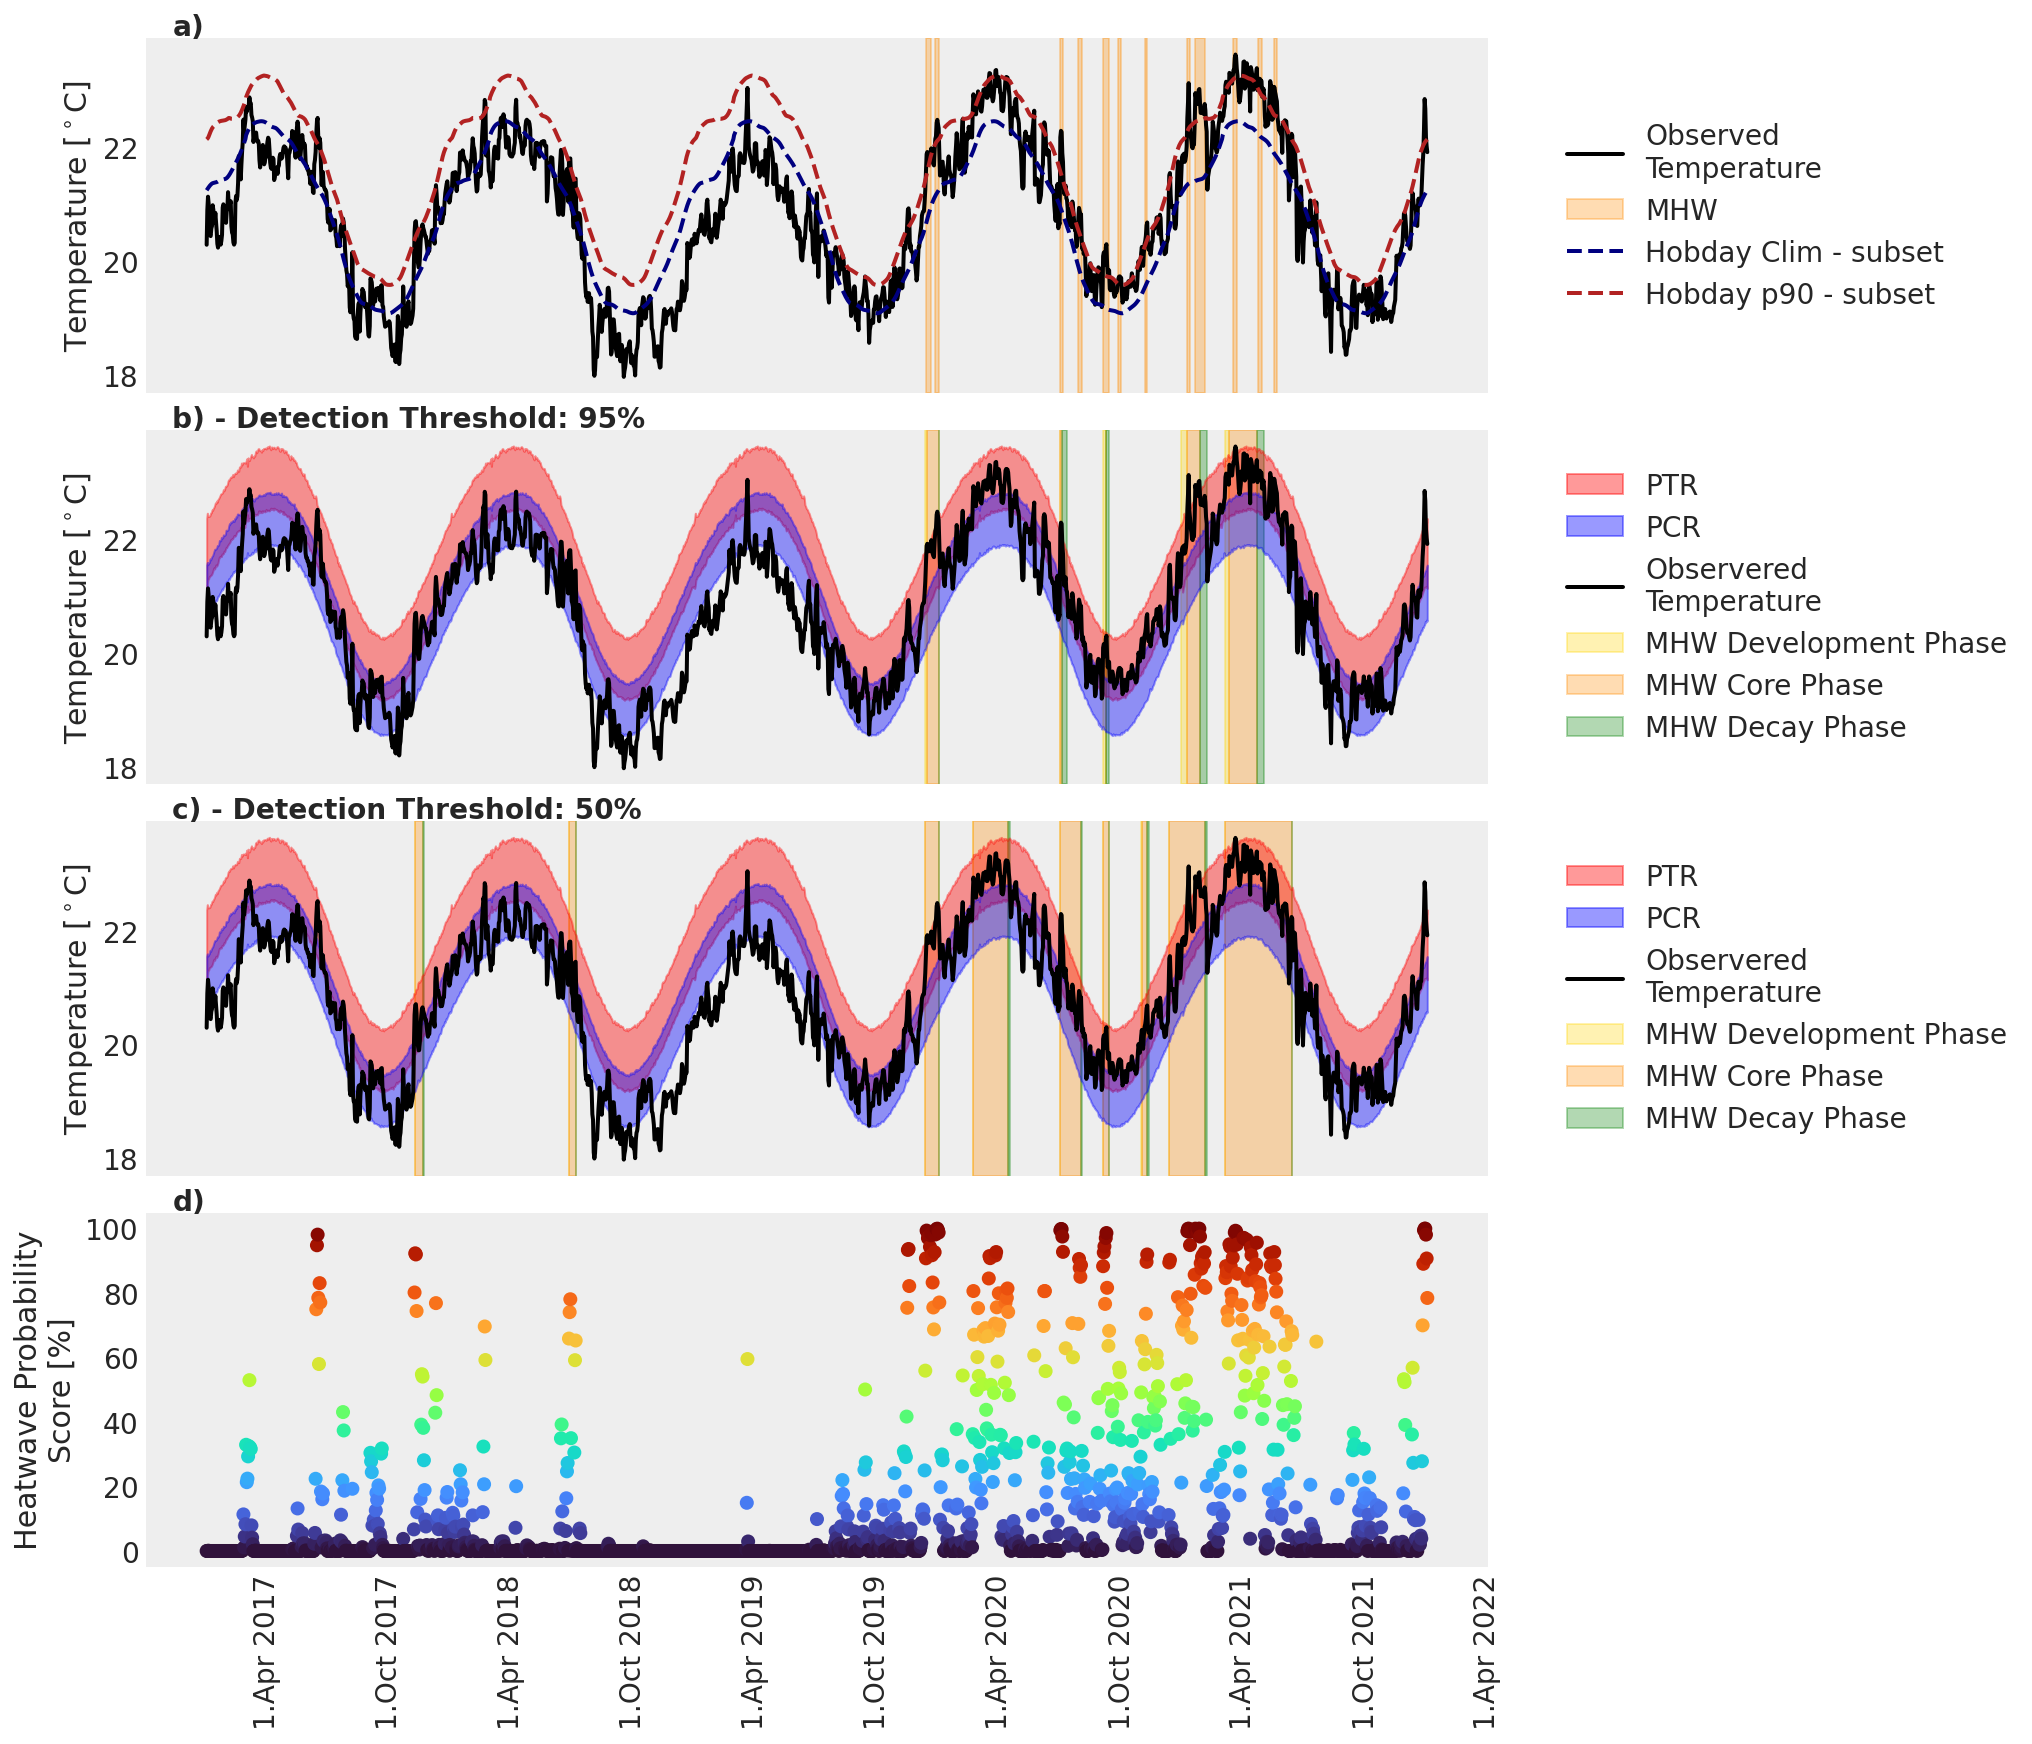

In [17]:
fig, axs = plt.subplots( ncols=1, nrows=4, figsize=(14, 12),sharey="row", sharex=True)
axs = axs.flatten()

# Set y-axis labels for each subplot
axs[0].set_ylabel("Temperature [$^\\circ$C]")
axs[1].set_ylabel("Temperature [$^\\circ$C]")
axs[2].set_ylabel("Temperature [$^\\circ$C]")
axs[3].set_ylabel("Heatwave Probability\nScore [%]")

# Posterior Climate Reference (PCR), Posterior Threshold Reference (PTR), time axis
PCR, PTR, time_array = get_PCRs_and_PTR(idata, df_C_roll)

# Heatwave Probability Score (PTR exceedance probability)
prob_PTR = calculate_prob_PTR(df_C_roll, PTR, variable="Temp")

detection_threshold=95
ax = axs[0]

# Plot observed rolling mean temperature
ax.plot( df_C_roll.index, df_C_roll.Temp,label="Observed\nTemperature", color="black", lw=2)

# Shade detected marine heatwaves
for ds_start, ds_end in zip(mhws_["date_start"][:-1], mhws_["date_end"][:-1]):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color="darkorange", alpha=0.3)
# Last event (with legend label)
ax.axvspan( pd.Timestamp(mhws_["date_start"][-1]), pd.Timestamp(mhws_["date_end"][-1]),color="darkorange", alpha=0.3, label="MHW")

# Hobday climatology & threshold (subset)
ax.plot(df_C_roll.index, clim_["seas"], color="navy", lw=2, ls="--", label="Hobday Clim - subset")
ax.plot(df_C_roll.index, clim_["thresh"], color="firebrick", lw=2, ls="--", label="Hobday p90 - subset")

ax = axs[1]

# Plot posterior ranges for PCR & PTR
plot_probs_range(PTR, time_array, ax, color="red", label="PTR", mean_line=False)
plot_probs_range(PCR, time_array, ax, color="blue", label="PCR", mean_line=False)

# Detect MHWs based on HPS (heatwave probability score)
mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR), T_obs=df_C_roll.Temp, PCR=PCR, PTR=PTR, time=df_C_roll.index,  
                                    detection_threshold=95, ramp_threshold=20, max_dip=10, min_duration=10)

# Overlay detected MHW phases
plot_mhw_phases( df_C_roll.Temp, np.array(prob_PTR), mhw_dict_hps, ax,detection_threshold=95, ramp_threshold=20)
ax.text(0.02, 1.07,  f'b) - Detection Threshold: 95%',transform=ax.transAxes,fontsize=14, fontweight="bold",va="top",
            ha="left", bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=0) )

ax = axs[2]

# Plot posterior ranges for PCR & PTR
plot_probs_range(PTR, time_array, ax, color="red", label="PTR", mean_line=False)
plot_probs_range(PCR, time_array, ax, color="blue", label="PCR", mean_line=False)

# Detect MHWs based on HPS (heatwave probability score)
mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR), T_obs=df_C_roll.Temp, PCR=PCR, PTR=PTR, time=df_C_roll.index,  
                                    detection_threshold=50, ramp_threshold=20, max_dip=10, min_duration=10)

# Overlay detected MHW phases
plot_mhw_phases( df_C_roll.Temp, np.array(prob_PTR), mhw_dict_hps, ax,detection_threshold=50, ramp_threshold=20)
ax.text(0.02, 1.07, f'c) - Detection Threshold: 50%',transform=ax.transAxes,fontsize=14, fontweight="bold",va="top",
            ha="left", bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=0) )

ax = axs[3]
scatter = ax.scatter( time_array, prob_PTR, c=prob_PTR, cmap="turbo")

# formatting for x-axis
date_format = mdates.DateFormatter("1.%b %Y")  # On Windows: use '%#d.%b'
month_locator = mdates.MonthLocator(interval=6)

for ax in axs:
    ax.xaxis.set_major_locator(month_locator)
    ax.xaxis.set_major_formatter(date_format)
    ax.tick_params(axis="x", rotation=90)  # Rotate for readability
    ax.grid()

ncols, nrows = 1, 3
legend_axes_indices = [(row + 1) * ncols - 1 for row in range(nrows)]  # last in each row

for idx in legend_axes_indices:
    ax = axs[idx]
    handles, labels = ax.get_legend_handles_labels()
    if handles:  # Only add legend if entries exist
        ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.05, 0.5),   borderaxespad=0,frameon=False)


labels = ["a)" ,'d)']
for ax, lab in zip(axs.flat[[0,3]], labels):
    ax.text(0.02, 1.07, lab,transform=ax.transAxes,fontsize=14, fontweight="bold",va="top",
            ha="left", bbox=dict(facecolor="white", alpha=0.0, edgecolor="none", pad=0) )

plt.savefig(os.path.join(figures_folder, f"PCR_PTR_detection_threhold.png"), dpi=300)
plt.savefig(os.path.join(figures_folder, f"PCR_PTR_detection_threhold.pdf"), dpi=300)
plt.show()


## Plot Traces

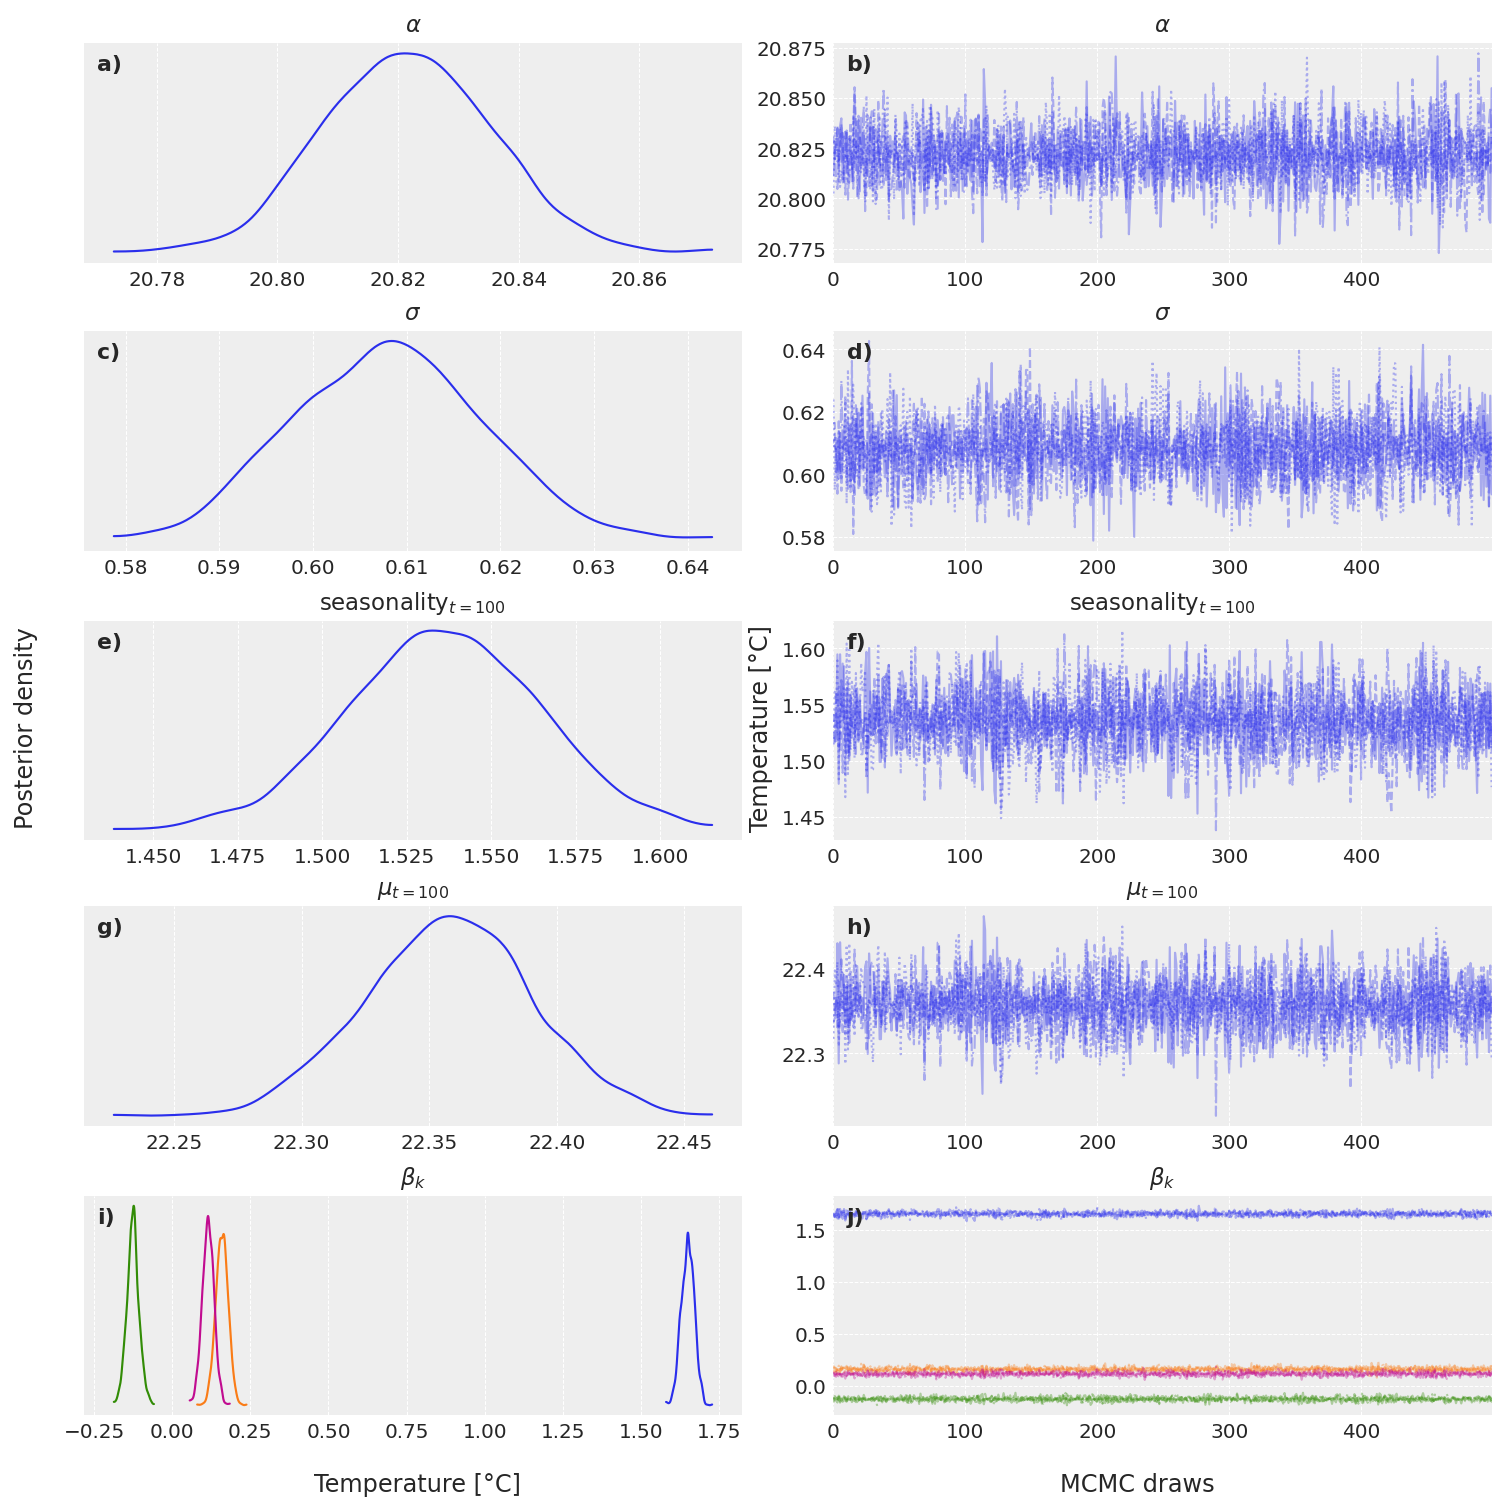

In [19]:
custom_labels = {
    "alpha": r"$\alpha$",
    "sigma": r"$\sigma$",
    "seasonality": r"$\text{seasonality}_{t=100}$",
    "mu": r"$\mu_{t=100}$",
    "beta_fourier": r"$\beta_{k}$",
}
time_idx = 100
fig_axes = az.plot_trace(
    idata,
    var_names=list(custom_labels.keys()),
    coords={"obs_id": [time_idx], "fourier_features": [0, 1, 2,3]},
    figsize=(10, 10),
    compact=True,
    combined=True,
    labeller=az.labels.MapLabeller(var_name_map=custom_labels),
)

fig = fig_axes[0, 0].figure
fig.text(0.25, -0.03, "Temperature [°C]", ha="center", fontsize=12)
fig.text(0.75, -0.03, "MCMC draws", ha="center", fontsize=12)
fig.text(-0.03, 0.5, "Posterior density", va="center",
         rotation="vertical", fontsize=12)
fig.text(0.48, 0.5, "Temperature [°C]", va="center",
         rotation="vertical", fontsize=12)


axes = fig.axes
for i, ax in enumerate(axes):
    label = f"{string.ascii_lowercase[i]})"
    ax.text(0.02, 0.95, label, transform=ax.transAxes,
            fontsize=11, fontweight='bold', va='top', ha='left')

fig.savefig(os.path.join(figures_folder,f"Trace_Plot.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(figures_folder,f"Trace_Plot.pdf"), dpi=300, bbox_inches="tight")
plt.show()

## ACF Plot

C:\Users\24048369\AppData\Local\Temp\ipykernel_37852\2575589017.py:25: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  n_chains = posterior.dims["chain"]
C:\Users\24048369\AppData\Local\Temp\ipykernel_37852\2575589017.py:62: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


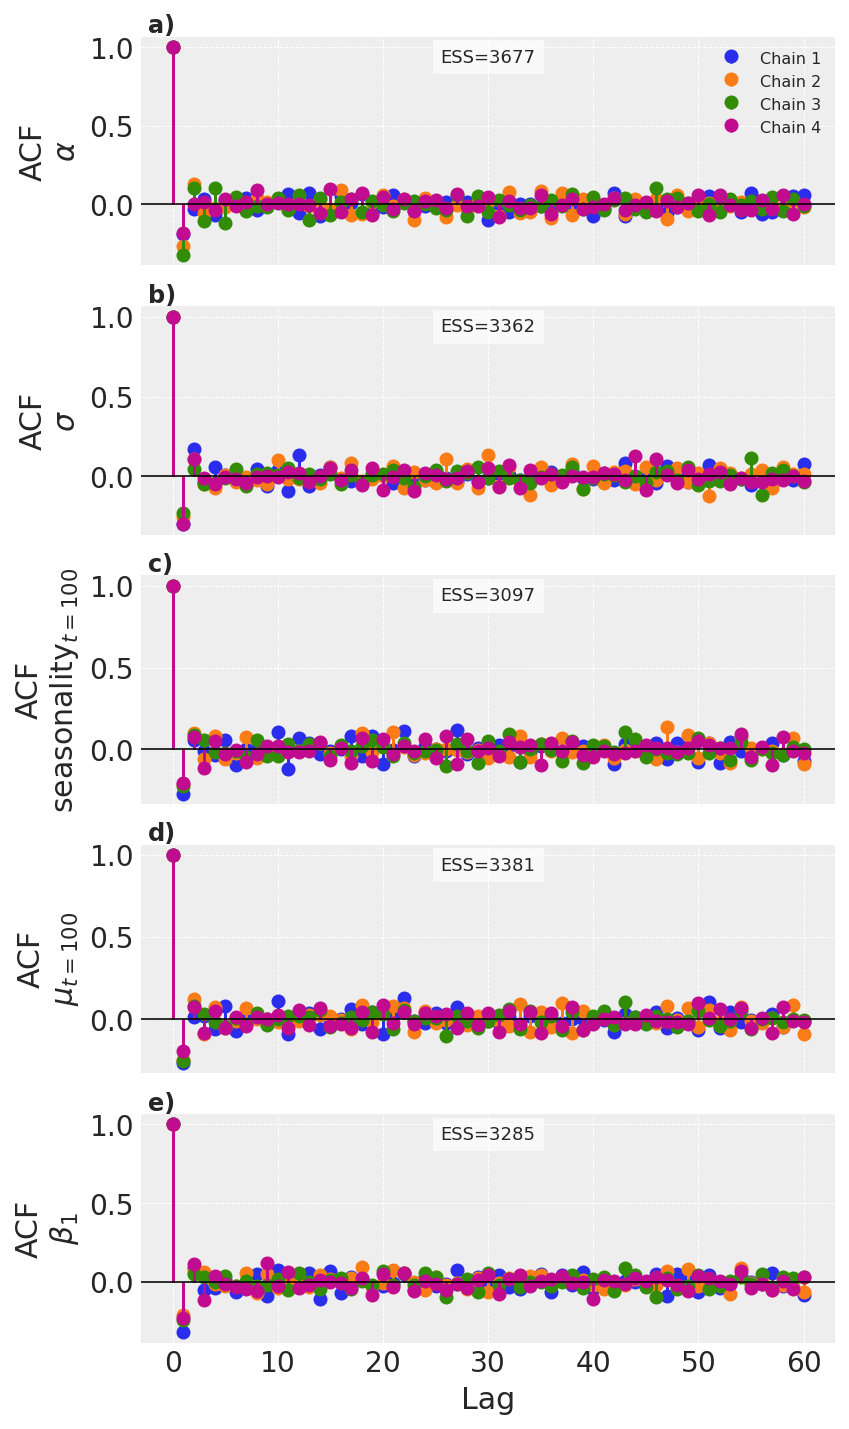

In [22]:
posterior = idata.posterior


acf_variables = {
    r"$\alpha$": posterior["alpha"].values,          # shape: (chains, draws)
    r"$\sigma$": posterior["sigma"].values,          # shape: (chains, draws)
     r"$\text{seasonality}_{t=100}$": posterior["seasonality"].sel(obs_id=100).values,  # (chains, draws)
    r"$\mu_{t=100}$": posterior["mu"].sel(obs_id=100).values,
     r"$\beta_{1}$": posterior["beta_fourier"].sel(fourier_features=0).values
}

ess_data = az.ess(idata, method="bulk")
ess_subset = {
    r"$\alpha$": ess_data["alpha"].values,
    r"$\sigma$": ess_data["sigma"].values,
    r"$\text{seasonality}_{t=100}$": ess_data["seasonality"].sel(obs_id=100).values,
    r"$\mu_{t=100}$": ess_data["mu"].sel(obs_id=100).values,
    r"$\beta_{1}$": ess_data["beta_fourier"].sel(fourier_features=0).values
}
    
max_lag = 60
n_vars = len(acf_variables)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
n_chains = posterior.dims["chain"]
colors = colors[:n_chains] 

fig, axes = plt.subplots(n_vars, 1, figsize=(6, 10), sharex='col')
for i, (ax, (name, samples)) in enumerate(zip(axes[:], acf_variables.items())):
    ax.text(0.01, 1.1, f"{string.ascii_lowercase[i]})", 
            transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top', ha='left')
    for chain_idx in range(n_chains):
        acf_vals = acf(samples[chain_idx], nlags=max_lag, fft=True)
        ax.stem(
            range(len(acf_vals)),
            acf_vals,
            basefmt=" ",
            linefmt=f"{colors[chain_idx]}",
            markerfmt=f"{colors[chain_idx]}",
            label=f"Chain {chain_idx+1}",
            # use_line_collection=True
        )
    ax.set_ylabel('ACF\n' + name)
    ax.axhline(0, color="black", lw=0.8)
    if i == 0:
        ax.legend(loc="upper right", fontsize=8)
        

axes[-1].set_xlabel("Lag")
for i, (ax, (name, samples)) in enumerate(zip(axes[:], ess_subset.items())):
    ax.text(0.5, 0.95, f"ESS={ess_subset[name]:.0f}", transform=ax.transAxes,
            ha="center", va="top", fontsize=9, bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

plt.tight_layout()
plt.savefig(os.path.join(figures_folder, "ACF_Plot.png"), dpi=300, bbox_inches="tight")
plt.savefig(os.path.join(figures_folder, "ACF_Plot.pdf"), dpi=300, bbox_inches="tight")
plt.show()

## Corner Plot

In [24]:
# Scalars
scalar_vars = ["alpha", "sigma"]

# Time-dependent variables
time_vars = ["seasonality", "mu"]

# Fourier coefficients
beta_var = "beta_fourier"
time_vars_labels = ["seasonality", "mu"]


# Choose one time index (for example, obs_id = 100)
time_idx = 100

# Extract scalars (chain, draw)
posterior = idata.posterior
data_scalars = posterior[scalar_vars].to_array().stack(sample=("chain", "draw")).values.T

# Extract time-dependent variables at one obs_id
data_time = posterior[time_vars].sel(obs_id=time_idx).to_array().stack(sample=("chain", "draw")).values.T
data_beta = posterior[beta_var].stack(sample=("chain", "draw")).values.T[:,0].reshape(-1, 1)  # shape (samples, fourier_features)

# Combine all into one array for corner
combined_data = np.hstack([data_scalars, data_time,
                           # data_time2,
                           data_beta])

# Create labels for the columns
labels_scalars = [ r"$\alpha$",r"$\sigma$"]

# Time-dependent variable labels (with obs_id = 100)
time_idx = 100
labels_time = [
    fr"$\text{{seasonality}}_{{t={time_idx}}}$"+ '\n',  # or a symbol if you prefer
    fr"$\mu_{{t={time_idx}}}$"]

# Beta Fourier coefficients, with k = 1..N
labels_beta = [
    fr"$\beta_{{k={i+1}}}$" for i in range(data_beta.shape[1])
]

# Combine all labels
labels = labels_scalars + labels_time + labels_beta

C:\Users\24048369\AppData\Local\anaconda3\envs\pymc_env_new\lib\site-packages\corner\core.py:133: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(


Quantiles:
[(0.05, np.float64(20.799380110264742)), (0.5, np.float64(20.821411181014213)), (0.95, np.float64(20.84443462273642))]
Quantiles:
[(0.05, np.float64(0.5916894815608046)), (0.5, np.float64(0.6081918628466573)), (0.95, np.float64(0.6250518396965545))]
Quantiles:
[(0.05, np.float64(1.4895756665467692)), (0.5, np.float64(1.5358065623811155)), (0.95, np.float64(1.5816037526738842))]
Quantiles:
[(0.05, np.float64(22.30345410719847)), (0.5, np.float64(22.357706850909178)), (0.95, np.float64(22.409950132257016))]
Quantiles:
[(0.05, np.float64(1.6166944129745435)), (0.5, np.float64(1.6510248974125032)), (0.95, np.float64(1.6836646338659342))]


C:\Users\24048369\AppData\Local\Temp\ipykernel_37852\3400395679.py:42: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(hspace=0.02, wspace=0.02)


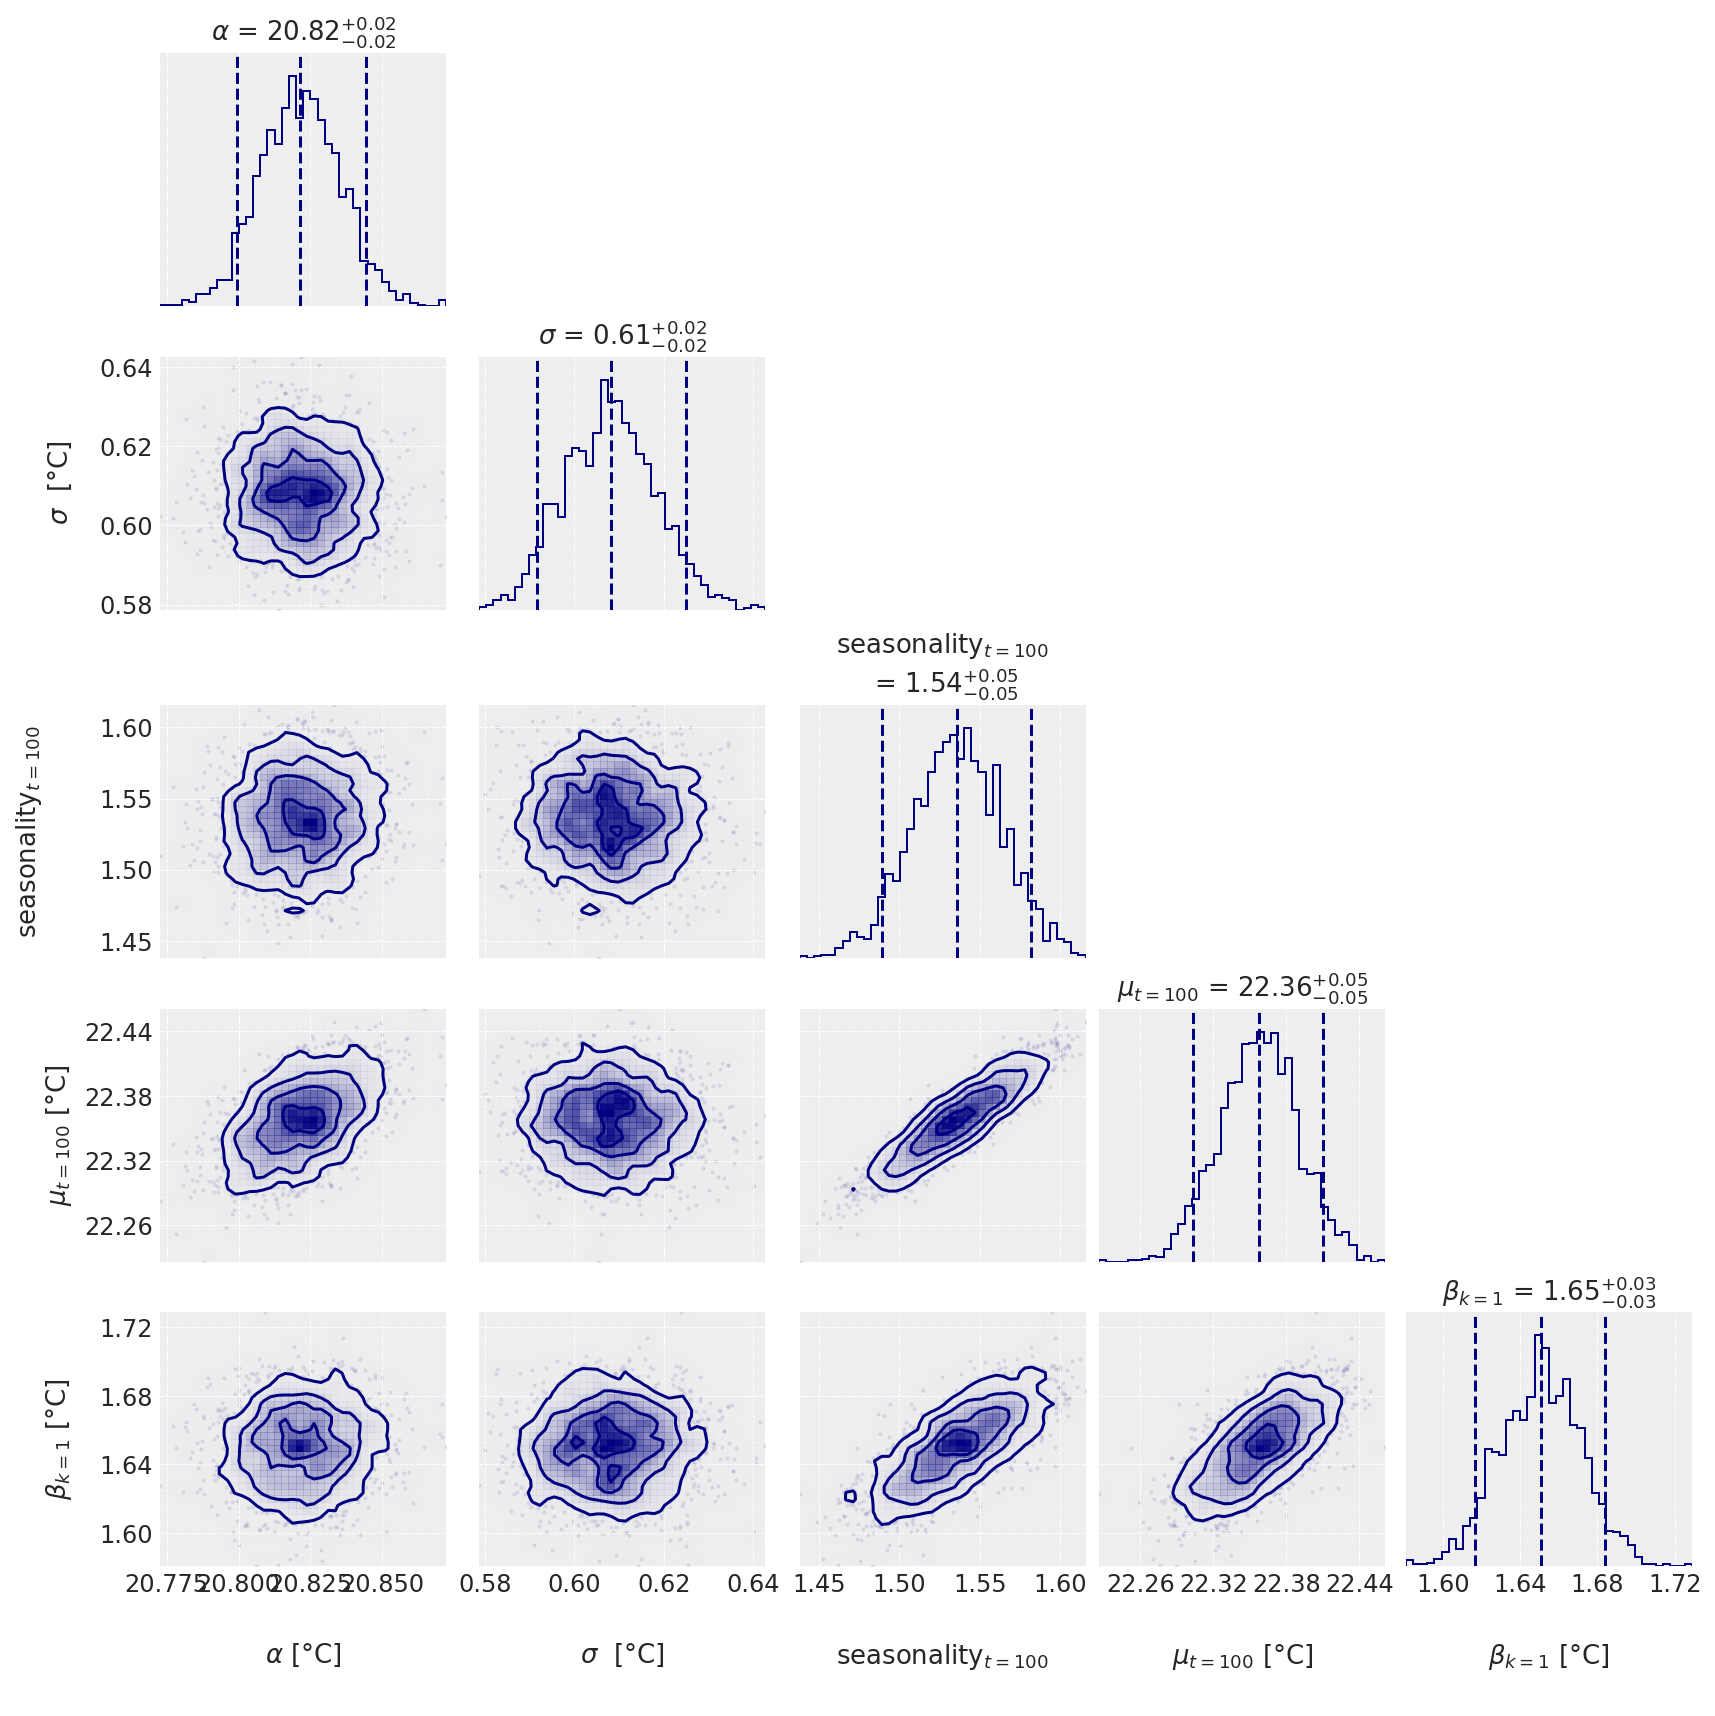

In [25]:
figure = corner.corner(
    combined_data,
    labels=labels,
    quantiles=[0.05, 0.5, 0.95],
    show_titles=True,
    verbose = True,
    title_kwargs={"fontsize": 13},
    label_kwargs={"fontsize": 13},           # larger axis labels (Greek letters look crisp)
    title_fmt=".2f",                         # cleaner numeric formatting
    bins=40,                                 # smoother histograms
    smooth=1.0,                              # Gaussian smoothing for contours
    color="navy",                       # nice color for contours
    plot_density=True,
    hist_kwargs={"color": "navy", "alpha": 1},
    max_n_ticks=4,                           # reduce clutter on axes
)


# Define which labels should have units
unit_labels = {
    r"$\alpha$": r"$\alpha$ [°C]",
    r"$\sigma$": r"$\sigma$  [°C]",
    r"$\text{seasonality}_{t=100}$\n": r"$\text{seasonality}_{t=100}$ [°C]",
    r"$\mu_{t=100}$": r"$\mu_{t=100}$ [°C]",
    r"$\beta_{k=1}$": r"$\beta_{k=1}$ [°C]"
}

# Update x and y axis labels accordingly
for ax in figure.get_axes():
    xlabel = ax.get_xlabel()
    ylabel = ax.get_ylabel()
    if xlabel in unit_labels:
        ax.set_xlabel(unit_labels[xlabel], fontsize=13)
    if ylabel in unit_labels:
        ax.set_ylabel(unit_labels[ylabel], fontsize=13)
        
    ax.tick_params(axis='both', labelsize=12, width=0.9, rotation = 0)
    

# Make layout tighter and nicer
plt.subplots_adjust(hspace=0.02, wspace=0.02)
figure.savefig(os.path.join(figures_folder,"Corner_Plot.png"), dpi=300, bbox_inches="tight")
figure.savefig(os.path.join(figures_folder,"Corner_Plot.pdf"), dpi=300, bbox_inches="tight")
plt.show()

## Plot PCR, PTR, and Hobday

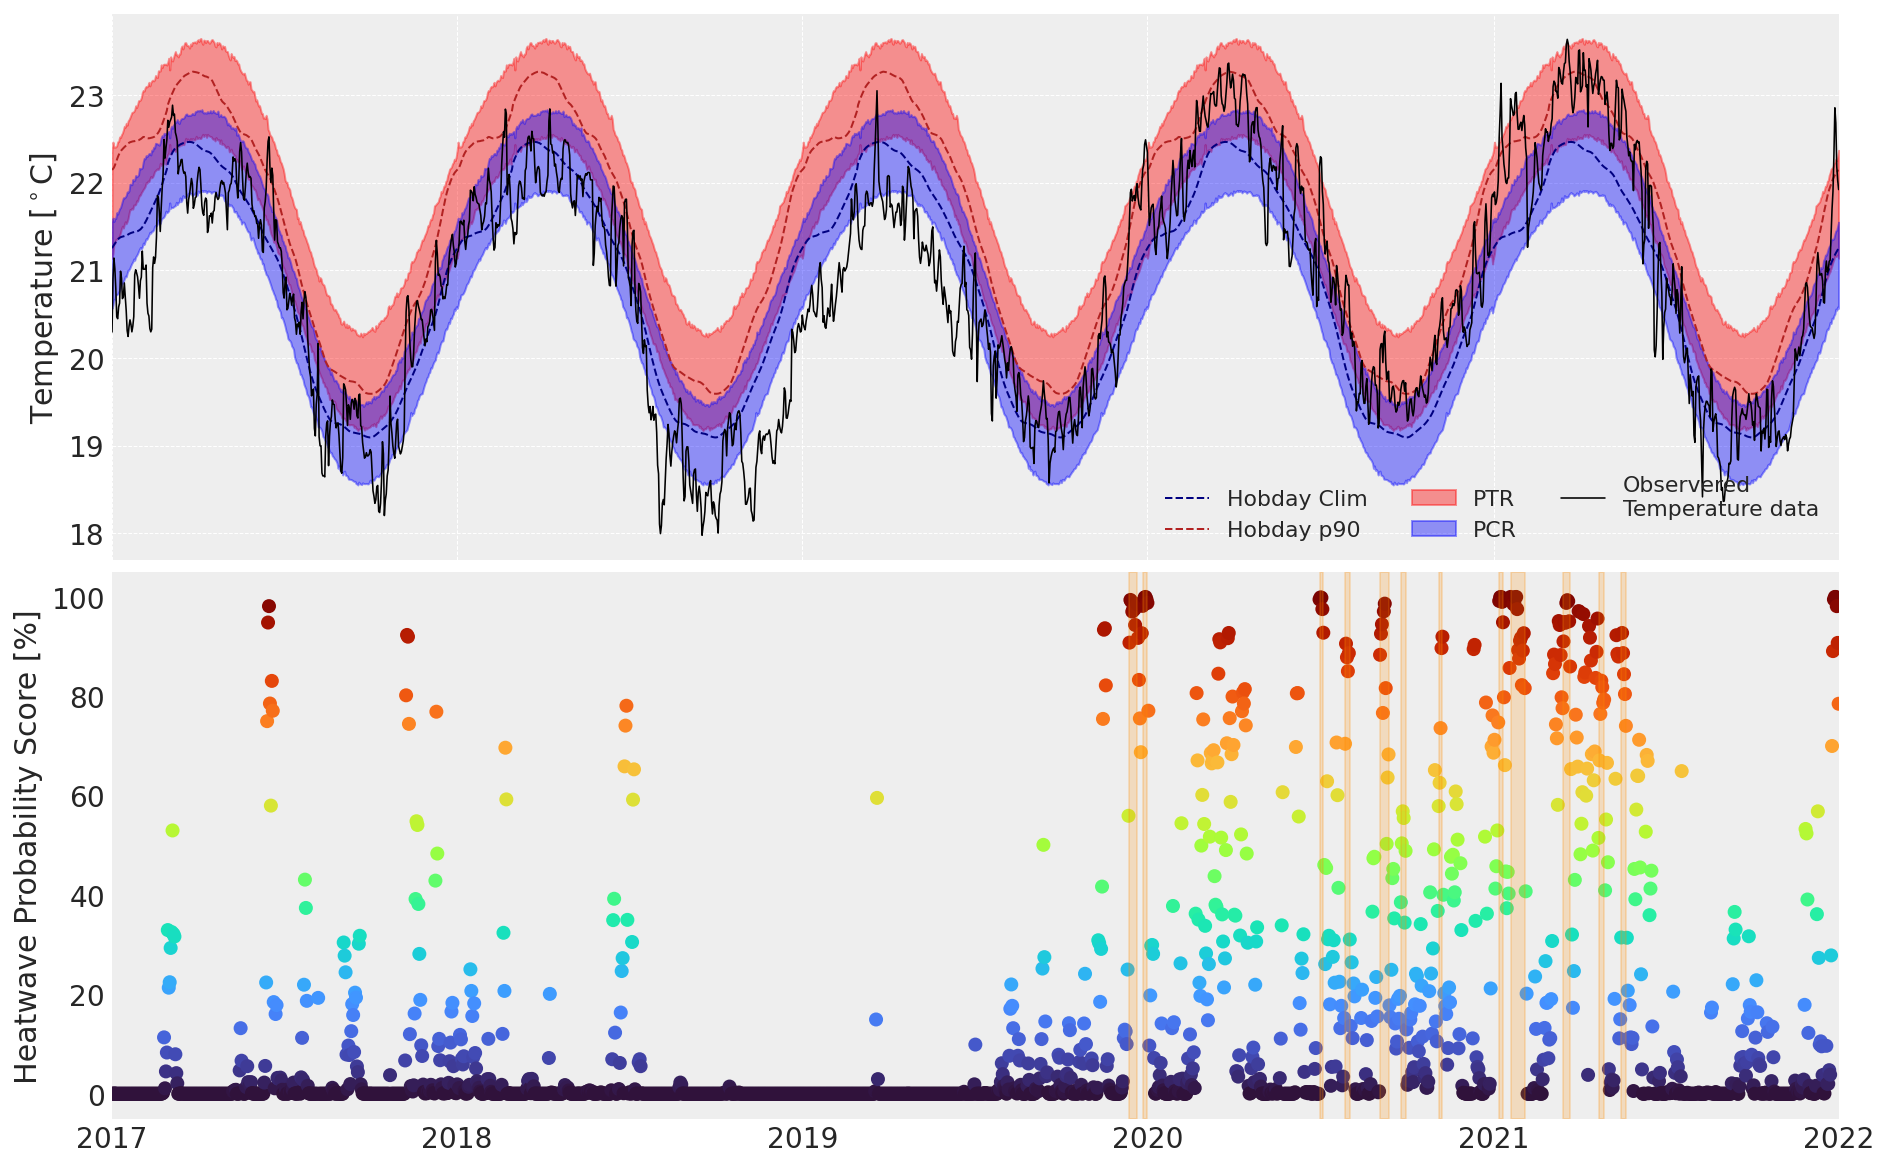

In [30]:
PCR, PTR, time_array = get_PCRs_and_PTR(idata,  df_C.iloc[:,:])
prob_PTR = calculate_prob_PTR(df_C.iloc[:,:], PTR, variable="Temp")

fig, axs = plt.subplots(ncols = 1, nrows =2,  figsize=(13, 8),sharey='row', sharex = True  )
ax = axs[0]
# plot short term hobday clim
mhw_small,clim_small,  timearray_small = comparing_to_Hobday(df_C.Temp)
ax.plot(df_C.index, clim_small['seas'], color = 'navy', lw = 1, ls ='--', label= 'Hobday Clim')
ax.plot(df_C.index, clim_small['thresh'], color = 'firebrick', lw = 1, ls ='--', label= 'Hobday p90')

# plot probabilty ranges
plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)

# PLot original timeseries
ax.plot(df_C.index, df_C.Temp, label = 'Observered\nTemperature data', color = 'black', lw =.8)

# plot legend
ax.legend(ncols = 3, fontsize = 11)
# ylabel 
ax.set_ylabel(f"Temperature [$^\\circ$C]")


#Plot exceendence probability score 
ax = axs[1]
ax.scatter(time_array, prob_PTR, c = prob_PTR, cmap = 'turbo')

# plot shaded areas of MHWs detected in 30year clim
for ds_start,ds_end in zip(mhws_['date_start'],mhws_['date_end']):
    ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.2)

ax.set_xlim(time_array[0],time_array[-1])
ax.set_ylabel('Heatwave Probability Score [%]')
ax.grid()              
   
plt.savefig(os.path.join(figures_folder, f"Temp_and_HPS_full_length.png"), dpi=300)
plt.savefig(os.path.join(figures_folder, f"Temp_and_HPS_full_length.pdf"), dpi=300)